# Kitaev chain defect operators

In [1]:
from pathlib import Path
import pickle
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [2]:
import numpy as np

# Load data

In [3]:
data_dir = Path("data/kitaev_chain_defect_operators")
with (data_dir / "results.pkl").open("rb") as f:
    data = np.asarray(pickle.load(f))

# The producing notebook stores rows on a uniform grid from 0 to 1.
parameters = np.linspace(0, 1, len(data))
if data.ndim != 2 or data.shape[1] not in (3, 4):
    raise ValueError("Expected left index, right index, ordinary overlap, and optional fermionic overlap.")
left_index, right_index, ordinary_overlap = data[:, :3].T
if data.shape[1] == 4:
    fermionic_overlap = data[:, 3]
else:
    # Older results pickles store the fermionic overlap in the companion CSV.
    graded = np.genfromtxt(data_dir / "graded_overlap.csv", delimiter=",", names=True)
    if graded.shape != parameters.shape or not np.allclose(graded["t"], parameters, rtol=0, atol=1e-12):
        raise ValueError("Index and overlap sweeps must use the same parameter grid.")
    fermionic_overlap = graded["graded_overlap"]

# Plot

In [4]:
data.shape

(201, 4)

In [5]:
critical_t = 1 / 3
# The bulk phase has no signed target exactly at the transition.
target = np.where(parameters < critical_t, 1., np.where(parameters > critical_t, -1., np.nan))
left_error = np.abs(left_index - target)
right_error = np.abs(right_index - target)
plot_floor = 1e-16

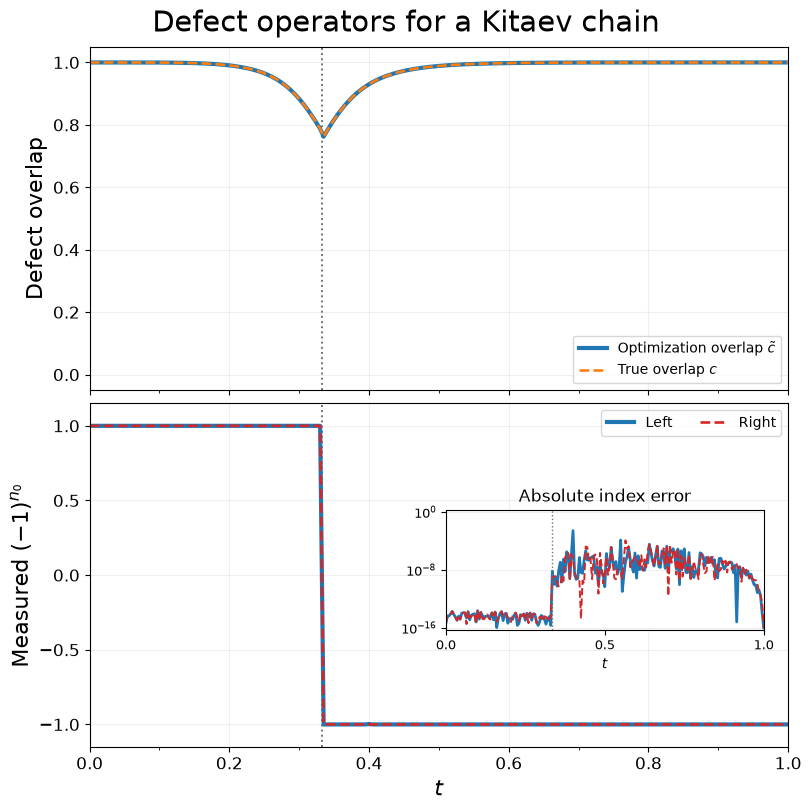

In [7]:
fig, (overlap_ax, index_ax) = plt.subplots(2, 1, figsize=(8, 8), sharex=True,
                                           layout="constrained")
fig.suptitle("Defect operators for a Kitaev chain", fontsize=21)

overlap_ax.plot(parameters, ordinary_overlap, color="tab:blue", lw=3,
                label=r"Optimization overlap $\tilde{c}$")
overlap_ax.plot(parameters, fermionic_overlap, color="tab:orange", lw=1.9, ls="--",
                label="True overlap $c$")
overlap_ax.set(ylabel=r"Defect overlap", ylim=(-0.05, 1.05))
overlap_ax.legend(loc="lower right")

# The solid line stays visible through the gaps in the dashed line when L = R.
index_ax.plot(parameters, left_index, color="tab:blue", lw=3, label="Left")
index_ax.plot(parameters, right_index, color="tab:red", lw=1.9, ls="--", label="Right")
index_ax.set(xlabel=r"$t$", ylabel=r"Measured $(-1)^{n_0}$", ylim=(-1.15, 1.15))
index_ax.legend(loc="upper right", ncol=2)

for ax in (overlap_ax, index_ax):
    ax.axvline(critical_t, color="0.45", ls=":", lw=1.4, zorder=0)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(.2))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(.1))
    ax.grid(which="major", alpha=.2)
    ax.tick_params(labelsize=12)
    ax.xaxis.label.set_size(16)
    ax.yaxis.label.set_size(16)

err_ax = index_ax.inset_axes([.51, .34, .455, .35])
err_ax.plot(parameters, np.maximum(left_error, plot_floor), color="tab:blue", lw=2)
err_ax.plot(parameters, np.maximum(right_error, plot_floor), color="tab:red", lw=1.4, ls="--")
err_ax.axvline(critical_t, color="0.45", ls=":", lw=1)
err_ax.set(yscale="log", xlim=(0, 1), ylim=(plot_floor / 2, 2),
           xticks=[0, .5, 1], yticks=[1e-16, 1e-8, 1],
           title="Absolute index error", xlabel=r"$t$")
err_ax.tick_params(labelsize=9)
err_ax.grid(axis="y", alpha=.2)

plot_dir = Path("plots")
plot_dir.mkdir(exist_ok=True)
for extension in ("pdf", "png"):
    fig.savefig(plot_dir / f"n0_kitaev_chain.{extension}", dpi=200, bbox_inches="tight")